# Frankenstein_3

Based on `Building_Energy_Flex/frankenstein_flow_based_v2.ipynb`. The plant
uses the original 3R2C building, quasi-steady heat pump and three-node
flow-based tank with smooth inversion mixing. FlexHouse THERM2 supplies
weather and indoor RH as a recorded input scenario. The comfort calculation
uses **Tmr = Ti** in the MPC and in the simulation.

### Run in Colab

Upload `ds3-5MinTHERM2.csv`, `met_poly.npz`, `clo_poly.npz` and `pmv.casadi`
through the Colab Files panel, then choose **Runtime → Run all**. The path
cell also supports the original folders when run from the local project root.
Start with a fresh runtime when switching CasADi versions.

The notebook follows the original order. You can run the data cell after
setup and configuration, the one-step plant check after the plant cells,
and the comfort check after loading the exports. The closed-loop cell
combines those parts and runs the original temperature objective alongside
a provisional PMV objective for review.

In [1]:
# Setup
import subprocess
import sys
from importlib.metadata import PackageNotFoundError, version

try:
    casadi_version = version("casadi")
except PackageNotFoundError:
    casadi_version = None

if casadi_version != "3.8.2":
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "casadi==3.8.2"])

In [2]:
from dataclasses import dataclass
from pathlib import Path

import casadi as ca
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.linalg import expm

if ca.__version__ != "3.8.2":
    raise RuntimeError("Restart the runtime and run the setup cells again to load CasADi 3.8.2.")

## Configuration

The building parameters, 10 kW heat pump, 250 L flow-based tank and
15-minute step come from the v2 notebook. The first example runs six hours with
the original six-hour prediction horizon. Both controller runs use the
same initial states and recorded disturbances. The Italian tariff
schedule in the original notebook is retained as an illustrative price
input for both runs.

In [62]:
# -----------------------------
# Global configuration
# -----------------------------
DT_HOURS = 0.25                    # 15 minutes
SIMULATION_HOURS = 6               # short comparison
PREDICTION_HOURS = 6               # MPC horizon
HORIZON_STEPS = int(PREDICTION_HOURS / DT_HOURS)

PRICE_BY_BAND_EUR_PER_KWH = {
    "F1": 0.3291,
    "F2": 0.3439,
    "F3": 0.3060,
}

# Building RC model parameters (preserved from build_RC_MPC as much as possible)
BUILDING_PARAMS = {
    "Rea": 58.4895,   # [°C/kW]
    "Rie": 1.1521,    # [°C/kW]
    "Rinf": 15.748,   # [°C/kW]
    "Ce": 3.5,        # [kWh/°C]
    "Ci": 1.15,       # [kWh/°C]
    "Ai": 1.56,       # [m²] effective solar aperture
    "Ae": 0.122,      # [m²] effective solar aperture
    "heating_efficiency": 1.0,
}

# Heat pump and tank baseline sizing
P_HP_NOMINAL_KW = 10.0
TANK_VOLUME_M3 = 25.0 / 1000.0 * P_HP_NOMINAL_KW  # 25 L/kW

# Flow-based tank / hydronic assumptions
T_TANK_PHYSICAL_MIN_C = 30.0
T_TANK_MAX_C = 60.0

T_HP_SUPPLY_C = 50.0          # HP supply temperature to tank [°C]
T_LOAD_RETURN_C = 30.0        # simplified return temperature from fan-coil/building [°C]
T_SUPPLY_MIN_C = 40.0         # minimum useful top-node temperature for heat delivery [°C]

M_DOT_HP_MAX_KG_S = 0.30
M_DOT_LOAD_MAX_KG_S = 0.20
Q_BUILD_MAX_KW = 6.0

# Terminal tank target: [bottom, middle, top]
T_TANK_TARGET_PROFILE_C = np.array([35.0, 40.0, 45.0], dtype=float)
TANK_TERMINAL_WEIGHT = 0.20

# Control penalties
TRACK_WEIGHT = 1.0
SLACK_WEIGHT = 1000.0
SMOOTH_WEIGHT = 0.02

# Comfort band
TI_MIN_C = 20.0
TI_MAX_C = 24.0
TI_REF_C = 22.0

# Recorded FlexHouse input scenario, in Copenhagen local time
START_TIME = "2009-03-09 07:00"
DATA_FILE = Path("ds3-5MinTHERM2.csv")
if not DATA_FILE.is_file():
    DATA_FILE = Path("Datasets Buildings") / "ds3-5MinTHERM2.csv"

MODEL_DIR = Path("Snippets_Frankenstein")
if not MODEL_DIR.is_dir():
    MODEL_DIR = Path(".")

# Scenario inputs for the exported regressors
INDOOR_AIR_SPEED = 0.10  # [m/s]
MET_AVG_3 = 1.10         # [met]
CLO_EWMA_5 = 0.75        # [clo]

COMFORT_COLUMNS = [
    "hour_sin", "doy_cos", "month", "is_weekend", "Tout_daily_C",
    "RH",  "air_speed_m_s",
]# "met_avg_3", "Clo_EWMA_5",

## FlexHouse input data

Read `time`, `Ta`, `G` and the eight indoor RH channels from THERM2. Average
three five-minute samples per interval and use the mean of the eight RH
sensors. Calendar features and daily outdoor means use Copenhagen local time.
The daily mean comes from the whole recorded day. In this replay the MPC
receives the recorded future inputs on its horizon, including fixed RH.
Indoor temperature comes from the legacy building simulation.

In [63]:
# -----------------------------
# Utilities
# -----------------------------
def discretize_linear_system(A: np.ndarray, B: np.ndarray, dt_hours: float) -> tuple[np.ndarray, np.ndarray]:
    """Discretize a continuous-time linear state-space model."""
    A = np.asarray(A, dtype=float)
    B = np.asarray(B, dtype=float)
    A_d = expm(A * dt_hours)
    B_d = np.linalg.solve(A, (A_d - np.eye(A.shape[0]))) @ B
    return A_d, B_d


def get_arera_time_band(timestamp: pd.Timestamp) -> str:
    """Return F1/F2/F3 using the standard Italian calendar-based time bands."""
    weekday = timestamp.weekday()  # Monday = 0
    hour = timestamp.hour + timestamp.minute / 60.0

    # Public holidays are ignored in this v1 and can be added later.
    if weekday <= 4:  # Monday-Friday
        if 8 <= hour < 19:
            return "F1"
        if (7 <= hour < 8) or (19 <= hour < 23):
            return "F2"
        return "F3"

    if weekday == 5:  # Saturday
        return "F2" if 7 <= hour < 23 else "F3"

    return "F3"  # Sunday


def load_d3_inputs(csv_path, start_time, simulation_hours, horizon_steps):
    if not Path(csv_path).is_file():
        raise FileNotFoundError("Upload ds3-5MinTHERM2.csv and set DATA_FILE to its path.")

    rh_columns = [f"HRelH{i}" for i in range(8)]
    raw = pd.read_csv(csv_path, usecols=["time", "Ta", "G"] + rh_columns)
    time_utc = pd.to_datetime(raw["time"], utc=True)
    raw["timestamp"] = time_utc.dt.tz_convert("Europe/Copenhagen").dt.tz_localize(None)
    raw = raw.set_index("timestamp").sort_index()
    if raw.index.has_duplicates:
        raise ValueError("The D3 input contains duplicate timestamps.")

    raw["Gv"] = raw["G"].clip(lower=0.0)
    raw["RH"] = raw[rh_columns].mean(axis=1, skipna=False)
    channels = raw[["Ta", "Gv", "RH"]]
    samples = channels.resample("15min")
    df = samples.mean().where(samples.count() == 3)
    daily = raw["Ta"].resample("D").agg(["mean", "count"])
    daily_mean = daily["mean"].where(daily["count"] == 288)
    df["Tout_daily_C"] = daily_mean.reindex(df.index.normalize()).to_numpy()

    simulation_steps = int(simulation_hours / DT_HOURS)
    timeline = pd.date_range(start_time, periods=simulation_steps + horizon_steps, freq="15min")
    df = df.reindex(timeline)
    if not np.isfinite(df.to_numpy(dtype=float)).all():
        raise ValueError("Choose a D3 interval with complete weather, RH and full-day outdoor means.")

    hour = df.index.hour + df.index.minute / 60 + df.index.second / 3600
    df["hour_sin"] = np.sin(2 * np.pi * hour / 24)
    df["doy_cos"] = np.cos(2 * np.pi * df.index.dayofyear / 365)
    df["month"] = df.index.month
    df["is_weekend"] = (df.index.dayofweek >= 5).astype(int)
    df["met_avg_3"] = MET_AVG_3
    df["Clo_EWMA_5"] = CLO_EWMA_5
    df["air_speed_m_s"] = INDOOR_AIR_SPEED
    df["band"] = [get_arera_time_band(timestamp) for timestamp in df.index]
    df["price_eur_per_kwh"] = df["band"].map(PRICE_BY_BAND_EUR_PER_KWH)
    df.index.name = "timestamp"
    return df.reset_index()


df_inputs = load_d3_inputs(DATA_FILE, START_TIME, SIMULATION_HOURS, HORIZON_STEPS)
print(f"FlexHouse rows: {len(df_inputs)} at 15-minute intervals")
df_inputs[["timestamp", "Ta", "Gv", "RH", "Tout_daily_C"]].head()

FlexHouse rows: 48 at 15-minute intervals


,timestamp,Ta,Gv,RH,Tout_daily_C
0,2009-03-09 07:00:00,1.035800,0.034917,29.599896,2.603165
1,2009-03-09 07:15:00,1.092195,0.050365,29.511375,2.603165
2,2009-03-09 07:30:00,1.058535,0.029456,29.607979,2.603165
3,2009-03-09 07:45:00,1.059313,0.041701,29.758104,2.603165
4,2009-03-09 08:00:00,1.161701,0.079390,29.805396,2.603165


In [65]:
df_inputs.describe()

,timestamp,Ta,Gv,RH,Tout_daily_C,hour_sin,doy_cos,month,is_weekend,met_avg_3,Clo_EWMA_5,air_speed_m_s,price_eur_per_kwh
count,48,48.000000,48.000000,48.000000,4.800000e+01,48.000000,4.800000e+01,48.0,48.0,4.800000e+01,48.00,4.800000e+01,48.000000
mean,2009-03-09 12:52:30,3.676136,0.128175,30.418023,2.603165e+00,-0.144587,3.896304e-01,3.0,0.0,1.100000e+00,0.75,1.000000e-01,0.330333
min,2009-03-09 07:00:00,1.035800,0.000000,29.511375,2.603165e+00,-1.000000,3.896304e-01,3.0,0.0,1.100000e+00,0.75,1.000000e-01,0.329100
25%,2009-03-09 09:56:15,2.397640,0.040451,29.771214,2.603165e+00,-0.840109,3.896304e-01,3.0,0.0,1.100000e+00,0.75,1.000000e-01,0.329100
50%,2009-03-09 12:52:30,3.741540,0.089235,30.354427,2.603165e+00,-0.226955,3.896304e-01,3.0,0.0,1.100000e+00,0.75,1.000000e-01,0.329100
75%,2009-03-09 15:48:45,5.115523,0.184431,31.099891,2.603165e+00,0.513893,3.896304e-01,3.0,0.0,1.100000e+00,0.75,1.000000e-01,0.329100
max,2009-03-09 18:45:00,6.165770,0.459845,31.479458,2.603165e+00,0.965926,3.896304e-01,3.0,0.0,1.100000e+00,0.75,1.000000e-01,0.343900
std,NaN,1.595657,0.118175,0.669459,2.243943e-15,0.699491,5.609859e-17,0.0,0.0,6.731830e-16,0.00,2.804929e-17,0.004134


## Building model

The building model keeps the original **3R2C** formulation and its parameter set.  
The only conceptual change is that the thermal input is now interpreted as:

\[
Q_{build}
\]

that is, the **thermal power effectively delivered to the building from the tank**, not directly from the heat pump.

In [34]:
# -----------------------------
# Building RC model
# -----------------------------
@dataclass
class BuildingRCParameters:
    Rea: float
    Rie: float
    Rinf: float
    Ce: float
    Ci: float
    Ai: float
    Ae: float
    heating_efficiency: float = 1.0


class BuildingRCModel:
    def __init__(self, params: BuildingRCParameters, dt_hours: float) -> None:
        self.params = params
        self.dt_hours = dt_hours

        A_c = np.array([
            [
                -1.0 / (params.Ci * params.Rie) - 1.0 / (params.Ci * params.Rinf),
                1.0 / (params.Ci * params.Rie),
            ],
            [
                1.0 / (params.Ce * params.Rie),
                -1.0 / (params.Ce * params.Rie) - 1.0 / (params.Ce * params.Rea),
            ],
        ])

        B_c = np.array([
            [1.0 / params.Ci, 1.0 / (params.Ci * params.Rinf), params.Ai / params.Ci],
            [0.0, 1.0 / (params.Ce * params.Rea), params.Ae / params.Ce],
        ])

        self.A_d, self.B_d = discretize_linear_system(A_c, B_c, dt_hours)

    def step_numpy(self, x_k: np.ndarray, q_build_kw: float, t_out_c: float, g_solar: float) -> np.ndarray:
        u_k = np.array([
            q_build_kw * self.params.heating_efficiency,
            t_out_c,
            g_solar,
        ])
        return self.A_d @ x_k + self.B_d @ u_k


building_model = BuildingRCModel(
    BuildingRCParameters(**BUILDING_PARAMS),
    dt_hours=DT_HOURS,
)

print("Discrete A matrix:")
print(np.round(building_model.A_d, 4))
print("\nDiscrete B matrix:")
print(np.round(building_model.B_d, 4))

Discrete A matrix:
[[0.8217 0.1657]
 [0.0544 0.944 ]]

Discrete B matrix:
[[0.1972 0.0126 0.3083]
 [0.0062 0.0016 0.0181]]


## Heat pump model

The heat pump is modeled in a quasi-steady way through:
- a **capacity map**,
- a **COP map**.

In this flow-based version, the sink-side temperature used by the HP map is the imposed heat-pump supply temperature to the tank, `T_HP_SUPPLY_C`.  
This avoids using the tank top node as both a storage state and a direct HP supply target.

In [35]:
# -----------------------------
# Heat pump model
# -----------------------------
@dataclass
class QuasiSteadyHeatPumpParameters:
    q_ref_kw: float
    cop_ref: float
    t_source_ref_c: float
    t_sink_ref_c: float
    alpha_q_src: float
    alpha_q_sink: float
    alpha_cop_src: float
    alpha_cop_sink: float


HP_PARAMS = QuasiSteadyHeatPumpParameters(
    q_ref_kw=P_HP_NOMINAL_KW,
    cop_ref=3.5,
    t_source_ref_c=7.0,
    t_sink_ref_c=35.0,
    alpha_q_src=0.20,
    alpha_q_sink=-0.08,
    alpha_cop_src=0.08,
    alpha_cop_sink=-0.04,
)


def hp_capacity_kw(t_source_c, t_sink_c, params: QuasiSteadyHeatPumpParameters):
    return (
        params.q_ref_kw
        + params.alpha_q_src * (t_source_c - params.t_source_ref_c)
        + params.alpha_q_sink * (t_sink_c - params.t_sink_ref_c)
    )


def hp_cop(t_source_c, t_sink_c, params: QuasiSteadyHeatPumpParameters):
    return (
        params.cop_ref
        + params.alpha_cop_src * (t_source_c - params.t_source_ref_c)
        + params.alpha_cop_sink * (t_sink_c - params.t_sink_ref_c)
    )


# Quick sanity check
print("Example HP operating point")
print("Q_max [kW]:", round(float(hp_capacity_kw(5.0, 40.0, HP_PARAMS)), 3))
print("COP [-]:", round(float(hp_cop(5.0, 40.0, HP_PARAMS)), 3))

Example HP operating point
Q_max [kW]: 9.2
COP [-]: 3.14


## Flow-based 3-node tank model

The tank is represented with three vertical nodes:

\[
T_{bottom}, \quad T_{middle}, \quad T_{top}
\]

The architecture is:

\[
HP
ightarrow Tank
ightarrow Building
\]

but the coupling is now flow-based rather than purely power-based.

### Heat pump side
The heat pump draws water from the bottom region and injects heated water at the top region.  
This is represented by an equivalent charging mass flow rate:

\[
\dot m_{hp}
\]

and a fixed HP supply temperature:

\[
T_{hp,supply}
\]

### Building/load side
The building draws hot water from the tank top and returns cooler water to the bottom.  
This is represented by an equivalent load-side mass flow rate:

\[
\dot m_{load}
\]

and a simplified return temperature:

\[
T_{load,return}
\]

The heat delivered to the building is therefore derived from the tank state:

\[
Q_{build} = \dot m_{load} c_p (T_{top} - T_{load,return})
\]

The model also includes inter-node conductance, ambient losses, and smooth anti-inversion mixing.

In [36]:
# -----------------------------
# 3-node flow-based tank model
# -----------------------------
@dataclass
class ThreeNodeTankParameters:
    volume_m3: float
    ua_total_kw_per_k: float
    g_between_nodes_kw_per_k: float
    t_min_c: float
    t_max_c: float
    t_hp_supply_c: float
    t_load_return_c: float
    t_supply_min_c: float
    m_dot_hp_max_kg_s: float
    m_dot_load_max_kg_s: float
    rho_kg_per_m3: float = 1000.0
    cp_kwh_per_kgk: float = 4180.0 / 3600.0 / 1000.0
    inversion_mixing_fraction: float = 0.10
    inversion_softplus_beta: float = 10.0


class ThreeNodeTankModel:
    """
    Three-node flow-based stratified tank.

    State ordering:
    - x[0] = bottom temperature [°C]
    - x[1] = middle temperature [°C]
    - x[2] = top temperature [°C]

    Decision variables:
    - m_dot_hp_kg_s: equivalent HP charging flow rate [kg/s]
    - m_dot_load_kg_s: equivalent load-side flow rate [kg/s]
    """

    def __init__(self, params: ThreeNodeTankParameters, dt_hours: float) -> None:
        self.params = params
        self.dt_hours = dt_hours

        c_total = params.rho_kg_per_m3 * params.volume_m3 * params.cp_kwh_per_kgk
        self.c_node_kwh_per_k = c_total / 3.0
        self.ua_node_kw_per_k = params.ua_total_kw_per_k / 3.0
        self.g_between_nodes_kw_per_k = params.g_between_nodes_kw_per_k

    @property
    def cp_flow_kw_per_kg_s_k(self) -> float:
        """
        Heat capacity for flow power calculations [kW / (kg/s K)].
        """
        return self.params.cp_kwh_per_kgk * 3600.0

    def q_hp_to_tank_kw_numpy(self, x_tank_c: np.ndarray, m_dot_hp_kg_s: float) -> float:
        """
        Thermal power transferred by HP into the tank [kW].
        Based on bottom-node suction and fixed HP supply temperature.
        """
        T_bottom = float(x_tank_c[0])
        return m_dot_hp_kg_s * self.cp_flow_kw_per_kg_s_k * (self.params.t_hp_supply_c - T_bottom)

    def q_tank_to_building_kw_numpy(self, x_tank_c: np.ndarray, m_dot_load_kg_s: float) -> float:
        """
        Thermal power delivered from tank to building [kW].
        Based on top-node supply and fixed load return temperature.
        """
        T_top = float(x_tank_c[2])
        return m_dot_load_kg_s * self.cp_flow_kw_per_kg_s_k * (T_top - self.params.t_load_return_c)

    def q_hp_to_tank_kw_casadi(self, x_tank_c, m_dot_hp_kg_s):
        T_bottom = x_tank_c[0]
        return m_dot_hp_kg_s * self.cp_flow_kw_per_kg_s_k * (self.params.t_hp_supply_c - T_bottom)

    def q_tank_to_building_kw_casadi(self, x_tank_c, m_dot_load_kg_s):
        T_top = x_tank_c[2]
        return m_dot_load_kg_s * self.cp_flow_kw_per_kg_s_k * (T_top - self.params.t_load_return_c)

    def _softplus_numpy(self, x: float | np.ndarray) -> float | np.ndarray:
        beta = self.params.inversion_softplus_beta
        xb = np.clip(beta * x, -50.0, 50.0)
        return np.log1p(np.exp(xb)) / beta

    def _softplus_casadi(self, x):
        beta = self.params.inversion_softplus_beta
        return ca.log(1.0 + ca.exp(beta * x)) / beta

    def smooth_inversion_mixing_numpy(self, temperatures_c: np.ndarray) -> np.ndarray:
        """
        Smooth local anti-inversion mixing term [K/h].
        """
        T = np.asarray(temperatures_c, dtype=float)

        eta = self.params.inversion_mixing_fraction
        if not (0.0 <= eta <= 1.0):
            raise ValueError("inversion_mixing_fraction must be between 0 and 1.")

        gamma_per_h = eta / (2.0 * self.dt_hours)

        s01 = self._softplus_numpy(T[0] - T[1])
        s12 = self._softplus_numpy(T[1] - T[2])

        return np.array([
            -gamma_per_h * s01,
             gamma_per_h * s01 - gamma_per_h * s12,
             gamma_per_h * s12,
        ])

    def smooth_inversion_mixing_casadi(self, temperatures_c):
        """
        CasADi equivalent of the smooth local anti-inversion mixing term [K/h].
        """
        T = temperatures_c

        eta = self.params.inversion_mixing_fraction
        gamma_per_h = eta / (2.0 * self.dt_hours)

        s01 = self._softplus_casadi(T[0] - T[1])
        s12 = self._softplus_casadi(T[1] - T[2])

        return ca.vertcat(
            -gamma_per_h * s01,
             gamma_per_h * s01 - gamma_per_h * s12,
             gamma_per_h * s12,
        )

    def rhs_numpy(
        self,
        x_tank_c: np.ndarray,
        m_dot_hp_kg_s: float,
        m_dot_load_kg_s: float,
        t_amb_c: float,
    ) -> np.ndarray:
        """
        Continuous-time right-hand side dT/dt [K/h].
        """
        T = np.asarray(x_tank_c, dtype=float)
        T_b, T_m, T_t = T

        cp_flow = self.cp_flow_kw_per_kg_s_k
        C_node = self.c_node_kwh_per_k
        g = self.g_between_nodes_kw_per_k
        ua = self.ua_node_kw_per_k

        # HP charging loop: hot water injected at top, equivalent downward displacement.
        q_hp_bottom = m_dot_hp_kg_s * cp_flow * (T_m - T_b)
        q_hp_middle = m_dot_hp_kg_s * cp_flow * (T_t - T_m)
        q_hp_top = m_dot_hp_kg_s * cp_flow * (self.params.t_hp_supply_c - T_t)

        # Load loop: hot water extracted from top, cooler return enters bottom.
        q_load_bottom = m_dot_load_kg_s * cp_flow * (self.params.t_load_return_c - T_b)
        q_load_middle = m_dot_load_kg_s * cp_flow * (T_b - T_m)
        q_load_top = m_dot_load_kg_s * cp_flow * (T_m - T_t)

        q_flow = np.array([
            q_hp_bottom + q_load_bottom,
            q_hp_middle + q_load_middle,
            q_hp_top + q_load_top,
        ])

        # Inter-node conductance.
        q_cond = np.array([
            g * (T_m - T_b),
            g * (T_b - T_m) + g * (T_t - T_m),
            g * (T_m - T_t),
        ])

        # Ambient losses, positive if ambient warms the node.
        q_loss = ua * (t_amb_c - T)

        dTdt = (q_flow + q_cond + q_loss) / C_node
        dTdt += self.smooth_inversion_mixing_numpy(T)

        return dTdt

    def rhs_casadi(
        self,
        x_tank_c,
        m_dot_hp_kg_s,
        m_dot_load_kg_s,
        t_amb_c,
    ):
        """
        CasADi-compatible continuous-time right-hand side dT/dt [K/h].
        """
        T_b = x_tank_c[0]
        T_m = x_tank_c[1]
        T_t = x_tank_c[2]

        cp_flow = self.cp_flow_kw_per_kg_s_k
        C_node = self.c_node_kwh_per_k
        g = self.g_between_nodes_kw_per_k
        ua = self.ua_node_kw_per_k

        q_hp_bottom = m_dot_hp_kg_s * cp_flow * (T_m - T_b)
        q_hp_middle = m_dot_hp_kg_s * cp_flow * (T_t - T_m)
        q_hp_top = m_dot_hp_kg_s * cp_flow * (self.params.t_hp_supply_c - T_t)

        q_load_bottom = m_dot_load_kg_s * cp_flow * (self.params.t_load_return_c - T_b)
        q_load_middle = m_dot_load_kg_s * cp_flow * (T_b - T_m)
        q_load_top = m_dot_load_kg_s * cp_flow * (T_m - T_t)

        q_flow = ca.vertcat(
            q_hp_bottom + q_load_bottom,
            q_hp_middle + q_load_middle,
            q_hp_top + q_load_top,
        )

        q_cond = ca.vertcat(
            g * (T_m - T_b),
            g * (T_b - T_m) + g * (T_t - T_m),
            g * (T_m - T_t),
        )

        q_loss = ca.vertcat(
            ua * (t_amb_c - T_b),
            ua * (t_amb_c - T_m),
            ua * (t_amb_c - T_t),
        )

        dTdt = (q_flow + q_cond + q_loss) / C_node
        dTdt += self.smooth_inversion_mixing_casadi(x_tank_c)

        return dTdt

    def step_numpy(
        self,
        x_k: np.ndarray,
        m_dot_hp_kg_s: float,
        m_dot_load_kg_s: float,
        t_amb_c: float,
    ) -> np.ndarray:
        """
        Forward-Euler plant step.
        """
        dTdt = self.rhs_numpy(
            x_tank_c=x_k,
            m_dot_hp_kg_s=m_dot_hp_kg_s,
            m_dot_load_kg_s=m_dot_load_kg_s,
            t_amb_c=t_amb_c,
        )
        x_next = np.asarray(x_k, dtype=float) + self.dt_hours * dTdt
        return np.clip(x_next, self.params.t_min_c, self.params.t_max_c)

    def step_casadi(
        self,
        x_k,
        m_dot_hp_kg_s,
        m_dot_load_kg_s,
        t_amb_c,
    ):
        """
        CasADi-compatible forward-Euler tank step used in the MPC prediction model.
        """
        dTdt = self.rhs_casadi(
            x_tank_c=x_k,
            m_dot_hp_kg_s=m_dot_hp_kg_s,
            m_dot_load_kg_s=m_dot_load_kg_s,
            t_amb_c=t_amb_c,
        )
        return x_k + self.dt_hours * dTdt


TANK_PARAMS = ThreeNodeTankParameters(
    volume_m3=TANK_VOLUME_M3,
    ua_total_kw_per_k=0.002,
    g_between_nodes_kw_per_k=0.08,
    t_min_c=T_TANK_PHYSICAL_MIN_C,
    t_max_c=T_TANK_MAX_C,
    t_hp_supply_c=T_HP_SUPPLY_C,
    t_load_return_c=T_LOAD_RETURN_C,
    t_supply_min_c=T_SUPPLY_MIN_C,
    m_dot_hp_max_kg_s=M_DOT_HP_MAX_KG_S,
    m_dot_load_max_kg_s=M_DOT_LOAD_MAX_KG_S,
    inversion_mixing_fraction=0.10,
    inversion_softplus_beta=10.0,
)

tank_model = ThreeNodeTankModel(TANK_PARAMS, dt_hours=DT_HOURS)

print(f"Tank volume [m³]: {TANK_VOLUME_M3:.3f}")
print(f"Node capacity [kWh/K]: {tank_model.c_node_kwh_per_k:.4f}")
print(f"cp for flow calculations [kW/(kg/s K)]: {tank_model.cp_flow_kw_per_kg_s_k:.3f}")
print(f"Physical tank bounds [°C]: {tank_model.params.t_min_c:.1f} -> {tank_model.params.t_max_c:.1f}")
print(f"Minimum useful top-node temperature [°C]: {tank_model.params.t_supply_min_c:.1f}")

Tank volume [m³]: 0.250
Node capacity [kWh/K]: 0.0968
cp for flow calculations [kW/(kg/s K)]: 4.180
Physical tank bounds [°C]: 30.0 -> 60.0
Minimum useful top-node temperature [°C]: 40.0


## One-step plant check

After the input and plant cells, run this snippet on its own with prescribed
flows. It gives a quick check of the v2 building and tank transitions.

In [37]:
weather = df_inputs.iloc[0]
test_tank_initial = np.array([35.0, 40.0, 45.0])
test_load_flow = 0.02  # [kg/s]
test_heat = tank_model.q_tank_to_building_kw_numpy(test_tank_initial, test_load_flow)
test_building = building_model.step_numpy(
    np.array([21.5, 21.5]), test_heat, weather["Ta"], weather["Gv"]
)
test_tank = tank_model.step_numpy(
    test_tank_initial, 0.02, test_load_flow, weather["Ta"]
)
print("One-step building [Ti, Te]:", np.round(test_building, 3))
print("One-step tank [bottom, middle, top]:", np.round(test_tank, 3))

One-step building [Ti, Te]: [21.5   21.476]
One-step tank [bottom, middle, top]: [35.975 39.933 43.891]


## Exported comfort models

Load the two polynomial regressors and the CasADi PMV function. The
polynomial feature order matches the current exports. The predicted MET
enters the CLO regression. PMV uses the same indoor air temperature for
both its air and mean radiant inputs.

The two history features are fixed scenario inputs for this first replay.
The current MET export expects an inclusive average that used the current
sample during training. The constants let us run this export with an
explicit occupant scenario. They have the same values in both runs.

In [43]:
# MET and CLO polynomial loaders
#Note#1: The CLO_EWMA_5 and MET_AVG_3 should be autoregressive (meaning that the new values should be calculated basedon pas values in the csv file)

#Note#2: "Tmrt" should be taken from the RC model instead of be set equal to "Tin"

def load_poly_function(path, function_name, n_features):
    if not path.is_file():
        raise FileNotFoundError(f"Upload {path.name} and check MODEL_DIR.")
    with np.load(path, allow_pickle=False) as p:
        powers = p["powers"]
        mean = p["mean"]
        scale = p["scale"]
        coef = p["coef"]
        intercept = float(p["intercept"][0])

    if powers.ndim != 2 or powers.shape[1] != n_features:
        raise ValueError(f"{path.name} must have {n_features} raw inputs.")
    if np.any(scale <= 0):
        raise ValueError(f"{path.name} contains an invalid scale.")

    x = ca.MX.sym("x", n_features)
    max_power = int(powers.max())
    xp = [[1.0] + [x[i] ** k for k in range(1, max_power + 1)] for i in range(n_features)]
    y = intercept
    for t in range(powers.shape[0]):
        term = 1.0
        for i in range(n_features):
            exponent = int(powers[t, i])
            if exponent > 0:
                term *= xp[i][exponent]
        y += coef[t] * (term - mean[t]) / scale[t]
    return ca.Function(function_name, [x], [y])


met_f = load_poly_function(MODEL_DIR / "met_poly.npz", "met_poly", 8)
clo_f = load_poly_function(MODEL_DIR / "clo_poly.npz", "clo_poly", 9)
pmv_path = MODEL_DIR / "pmv.casadi"
if not pmv_path.is_file():
    raise FileNotFoundError("Upload pmv.casadi and check MODEL_DIR.")
pmv_f = ca.Function.load(str(pmv_path))


def predict_comfort(ti, context,met_mean,clo_mean):
    # context follows COMFORT_COLUMNS
    hour_sin = context[0]
    doy_cos = context[1]
    month = context[2]
    is_weekend = context[3]
    tout_daily = context[4]
    rh = context[5]
    air_speed = context[6]
    met_average = met_mean#context[6]
    clo_average = clo_mean#context[7]


    common = [hour_sin, doy_cos, month, is_weekend, tout_daily, ti]
    met = met_f(ca.vertcat(*common, rh, met_average))
    clo = clo_f(ca.vertcat(*common, ti * rh, clo_average, met))
    tmr = ti
    pmv = pmv_f(ca.vertcat(ti, tmr, air_speed, rh, met, clo))
    return met, clo, pmv

In [44]:
# Independent numeric comfort check after loading the exports
test_context = [0.9, 0.4, 3, 0, 2.6, 31.0, 1.10, 0.75, 0.10]
met, clo, pmv = predict_comfort(21.5, test_context)
print(f"Comfort check: MET={float(met):.3f}, CLO={float(clo):.3f}, PMV={float(pmv):+.3f}")

TypeError: predict_comfort() missing 2 required positional arguments: 'met_mean' and 'clo_mean'

## Economic MPC formulation

The two modes share the v2 plant dynamics, flow and power bounds, soft
temperature limits, energy cost, input smoothing and terminal tank target.
Two constraints keep the tank nodes ordered from bottom to top at each
prediction step, including the terminal state.
The temperature mode uses the original 22 °C tracking term. The PMV test mode replaces
that tracking term with the editable block below. At stage `k`, both
modes use the indoor state at the start of the interval, as in the
original cost. The first command is applied to the legacy plant.

In [45]:
# Edit this block after agreeing on the PMV objective.
# The quadratic penalty and weight are provisional for the first solve.
PMV_TEST_WEIGHT = 1.0


def pmv_stage_cost(pmv_value):
    return PMV_TEST_WEIGHT * pmv_value ** 2

In [72]:
# -----------------------------
# MPC builder
# -----------------------------
def build_economic_mpc_solver(
    building_model: BuildingRCModel,
    tank_model: ThreeNodeTankModel,
    hp_params: QuasiSteadyHeatPumpParameters,
    horizon_steps: int,
    comfort_mode: str = "temperature",
):
    if comfort_mode not in ("temperature", "pmv_test"):
        raise ValueError("Choose 'temperature' or 'pmv_test'.")
    opti = ca.Opti()

    # States
    X_build = opti.variable(2, horizon_steps + 1)  # [Ti, Te]
    X_tank = opti.variable(3, horizon_steps + 1)   # [T_bottom, T_middle, T_top]

    # Controls: equivalent hydronic flow rates
    M_dot_hp = opti.variable(1, horizon_steps)
    M_dot_load = opti.variable(1, horizon_steps)

    # Soft comfort constraints
    eps_low = opti.variable(1, horizon_steps)
    eps_high = opti.variable(1, horizon_steps)

    # Parameters / forecasts
    x0_build = opti.parameter(2)
    x0_tank = opti.parameter(3)
    ta_forecast = opti.parameter(1, horizon_steps)
    gh_forecast = opti.parameter(1, horizon_steps)
    price_forecast = opti.parameter(1, horizon_steps)
    comfort_forecast = None
    met_mean_forecast = None
    clo_mean_forecast = None
    if comfort_mode == "pmv_test":
        comfort_forecast = opti.parameter(len(COMFORT_COLUMNS), horizon_steps)
        met_mean_forecast = opti.parameter(1,horizon_steps)
        clo_mean_forecast = opti.parameter(1,horizon_steps)

    # Initial conditions
    opti.subject_to(X_build[:, 0] == x0_build)
    opti.subject_to(X_tank[:, 0] == x0_tank)

    # Keep bottom <= middle <= top across the whole horizon.
    opti.subject_to(X_tank[0, :] <= X_tank[1, :])
    opti.subject_to(X_tank[1, :] <= X_tank[2, :])

    objective = 0

    A_b = ca.DM(building_model.A_d)
    B_b = ca.DM(building_model.B_d)

    tank_target = ca.DM(T_TANK_TARGET_PROFILE_C)

    for k in range(horizon_steps):
        # Derived thermal powers
        q_hp_to_tank = tank_model.q_hp_to_tank_kw_casadi(
            x_tank_c=X_tank[:, k],
            m_dot_hp_kg_s=M_dot_hp[0, k],
        )
        q_tank_to_building = tank_model.q_tank_to_building_kw_casadi(
            x_tank_c=X_tank[:, k],
            m_dot_load_kg_s=M_dot_load[0, k],
        )

        # Building dynamics: original 3R2C structure, with tank-delivered heat input
        u_build = ca.vertcat(
            q_tank_to_building * building_model.params.heating_efficiency,
            ta_forecast[0, k],
            gh_forecast[0, k],
        )
        x_build_next = A_b @ X_build[:, k] + B_b @ u_build
        opti.subject_to(X_build[:, k + 1] == x_build_next)

        # Flow-based tank dynamics
        x_tank_next = tank_model.step_casadi(
            x_k=X_tank[:, k],
            m_dot_hp_kg_s=M_dot_hp[0, k],
            m_dot_load_kg_s=M_dot_load[0, k],
            t_amb_c=ta_forecast[0, k],
        )
        opti.subject_to(X_tank[:, k + 1] == x_tank_next)

        # HP algebraic maps using fixed HP supply temperature as sink-side condition
        q_hp_max = hp_capacity_kw(ta_forecast[0, k], tank_model.params.t_hp_supply_c, hp_params)
        cop_k = hp_cop(ta_forecast[0, k], tank_model.params.t_hp_supply_c, hp_params)

        # Flow bounds
        opti.subject_to(M_dot_hp[0, k] >= 0.0)
        opti.subject_to(M_dot_hp[0, k] <= tank_model.params.m_dot_hp_max_kg_s)
        opti.subject_to(M_dot_load[0, k] >= 0.0)
        opti.subject_to(M_dot_load[0, k] <= tank_model.params.m_dot_load_max_kg_s)

        # Derived heat-flow bounds
        opti.subject_to(q_hp_to_tank >= 0.0)
        opti.subject_to(q_hp_to_tank <= q_hp_max)
        opti.subject_to(q_tank_to_building >= 0.0)
        opti.subject_to(q_tank_to_building <= Q_BUILD_MAX_KW)

        # Tank state bounds
        opti.subject_to(X_tank[:, k] >= tank_model.params.t_min_c)
        opti.subject_to(X_tank[:, k] <= tank_model.params.t_max_c)

        # Minimum useful supply temperature from the top node
        opti.subject_to(X_tank[2, k] >= tank_model.params.t_supply_min_c)

        # Comfort soft constraints
        opti.subject_to(eps_low[0, k] >= 0.0)
        opti.subject_to(eps_high[0, k] >= 0.0)
        opti.subject_to(X_build[0, k] + eps_low[0, k] >= TI_MIN_C)
        opti.subject_to(X_build[0, k] - eps_high[0, k] <= TI_MAX_C)

        # Stage cost
        p_hp_el_kw = q_hp_to_tank / cop_k
        objective += price_forecast[0, k] * p_hp_el_kw * DT_HOURS
        if comfort_mode == "pmv_test":
            _, _, pmv_k = predict_comfort(X_build[0, k], comfort_forecast[:, k],met_mean_forecast[0,k],clo_mean_forecast[0,k])
            objective += pmv_stage_cost(pmv_k)
        else:
            objective += TRACK_WEIGHT * (X_build[0, k] - TI_REF_C) ** 2
        objective += SLACK_WEIGHT * (eps_low[0, k] ** 2 + eps_high[0, k] ** 2)

        # Flow-rate smoothing
        if k > 0:
            objective += SMOOTH_WEIGHT * (
                (M_dot_hp[0, k] - M_dot_hp[0, k - 1]) ** 2
                + (M_dot_load[0, k] - M_dot_load[0, k - 1]) ** 2
            )

    # Terminal tank bounds and terminal storage value
    opti.subject_to(X_tank[:, -1] >= tank_model.params.t_min_c)
    opti.subject_to(X_tank[:, -1] <= tank_model.params.t_max_c)
    opti.subject_to(X_tank[2, -1] >= tank_model.params.t_supply_min_c)

    terminal_error = X_tank[:, -1] - tank_target
    objective += TANK_TERMINAL_WEIGHT * ca.sumsqr(terminal_error)

    opti.minimize(objective)

    # Initial guesses improve robustness for the nonlinear flow-based formulation.
    opti.set_initial(X_build[0, :], TI_REF_C)
    opti.set_initial(X_build[1, :], TI_REF_C)
    opti.set_initial(X_tank[0, :], T_TANK_TARGET_PROFILE_C[0])
    opti.set_initial(X_tank[1, :], T_TANK_TARGET_PROFILE_C[1])
    opti.set_initial(X_tank[2, :], T_TANK_TARGET_PROFILE_C[2])
    opti.set_initial(M_dot_hp, 0.05)
    opti.set_initial(M_dot_load, 0.05)

    opti.solver(
        "ipopt",
        {"print_time": False},
        {"print_level": 0, "max_iter": 300},
    )

    return opti, {
        "X_build": X_build,
        "X_tank": X_tank,
        "M_dot_hp": M_dot_hp,
        "M_dot_load": M_dot_load,
        "eps_low": eps_low,
        "eps_high": eps_high,
        "x0_build": x0_build,
        "x0_tank": x0_tank,
        "ta_forecast": ta_forecast,
        "gh_forecast": gh_forecast,
        "price_forecast": price_forecast,
        "comfort_forecast": comfort_forecast,
        "met_mean_forecast": met_mean_forecast,
        "clo_mean_forecast": clo_mean_forecast,
        "horizon_steps": horizon_steps,
    }

## Closed-loop simulation

Build a controller for each mode. For every 15-minute interval, load the
next forecast window, solve the MPC and apply its first action. Record
comfort at the start of the interval to match the prediction cost. Keep
the end-of-interval tank mean for checking stored heat at the end.

In [73]:
# -----------------------------
# Closed-loop simulation
# -----------------------------
def run_closed_loop_simulation(df, building_model, tank_model, hp_params, opti, mpc_vars):
    x_build = np.array([21.5, 21.5], dtype=float)      # [Ti, Te]
    x_tank = np.array([35.0, 40.0, 45.0], dtype=float) # [bottom, middle, top]
    records = []
    horizon_steps = mpc_vars["horizon_steps"]
    n_steps = len(df) - horizon_steps
    if n_steps <= 0:
        raise ValueError("The replay must contain simulation rows plus the prediction horizon.")


    #Historical Clo and Met
    met_history = [1.10]*4
    clo_history = [0.75]*4
    for k in range(n_steps):
        window = df.iloc[k:k + horizon_steps]
        ta_fc = window["Ta"].to_numpy(dtype=float).reshape(1, -1)
        gh_fc = window["Gv"].to_numpy(dtype=float).reshape(1, -1)
        price_fc = window["price_eur_per_kwh"].to_numpy(dtype=float).reshape(1, -1)
        #print(window)
        opti.set_value(mpc_vars["x0_build"], x_build)
        opti.set_value(mpc_vars["x0_tank"], x_tank)
        opti.set_value(mpc_vars["ta_forecast"], ta_fc)
        opti.set_value(mpc_vars["gh_forecast"], gh_fc)
        opti.set_value(mpc_vars["price_forecast"], price_fc)
        if mpc_vars["comfort_forecast"] is not None:
            comfort_fc = window[COMFORT_COLUMNS].to_numpy(dtype=float).T
            met_fc = window["met_avg_3"].to_numpy(dtype=float).reshape(1, -1)
            clo_fc = window["Clo_EWMA_5"].to_numpy(dtype=float).reshape(1, -1)
            opti.set_value(mpc_vars["comfort_forecast"], comfort_fc)
            opti.set_value(mpc_vars["met_mean_forecast"], met_fc)
            opti.set_value(mpc_vars["clo_mean_forecast"], clo_fc)

        # Start the nonlinear solve near the current thermal states.
        opti.set_initial(mpc_vars["X_build"], np.tile(x_build[:, None], (1, horizon_steps + 1)))
        opti.set_initial(mpc_vars["X_tank"], np.tile(x_tank[:, None], (1, horizon_steps + 1)))
        opti.set_initial(mpc_vars["M_dot_hp"], 0.05)
        opti.set_initial(mpc_vars["M_dot_load"], 0.05)
        opti.set_initial(mpc_vars["eps_low"], 0.0)
        opti.set_initial(mpc_vars["eps_high"], 0.0)

        try:
            solution = opti.solve()
            m_dot_hp_cmd = float(solution.value(mpc_vars["M_dot_hp"][0, 0]))
            m_dot_load_cmd = float(solution.value(mpc_vars["M_dot_load"][0, 0]))
            predicted_tank = solution.value(mpc_vars["X_tank"])
        except RuntimeError as exc:
            raise RuntimeError(f"MPC failed at step {k}, {df['timestamp'].iloc[k]}.") from exc

        row = df.iloc[k]
        ti_k, te_k = x_build
        tank_bottom, tank_middle, tank_top = x_tank
        context = row[COMFORT_COLUMNS].to_numpy(dtype=float)

        met_mean = np.mean(met_history)
        clo_mean = np.mean(clo_history)


        met, clo, pmv = predict_comfort(ti_k, context, met_mean, clo_mean)
        print("MET mean:",met_mean,"  met history:",met_history)
        #print("CLO mean:",clo_mean,"  clo history:",clo_history
        met_history = met_history[1:] + [float(met)]
        clo_history = clo_history[1:] + [float(clo)]

        q_hp_cmd = tank_model.q_hp_to_tank_kw_numpy(x_tank, m_dot_hp_cmd)
        q_build_cmd = tank_model.q_tank_to_building_kw_numpy(x_tank, m_dot_load_cmd)
        cop = float(hp_cop(row["Ta"], tank_model.params.t_hp_supply_c, hp_params))
        p_hp_kw = q_hp_cmd / max(cop, 1.1)
        x_build = building_model.step_numpy(x_build, q_build_cmd, row["Ta"], row["Gv"])
        x_tank = tank_model.step_numpy(x_tank, m_dot_hp_cmd, m_dot_load_cmd, row["Ta"])

        records.append({
            "timestamp": row["timestamp"],
            "elapsed_h": k * DT_HOURS,
            "Ta_C": row["Ta"],
            "RH_pct": row["RH"],
            "price_eur_per_kwh": row["price_eur_per_kwh"],
            "m_dot_hp_kg_s": m_dot_hp_cmd,
            "m_dot_load_kg_s": m_dot_load_cmd,
            "Q_hp_kw": q_hp_cmd,
            "Q_build_kw": q_build_cmd,
            "P_hp_kw": p_hp_kw,
            "COP": cop,
            "Ti_C": ti_k,
            "Te_C": te_k,
            "Tmr_C": ti_k,
            "MET": float(met),
            "CLO": float(clo),
            "PMV": float(pmv),
            "T_tank_bottom_C": tank_bottom,
            "T_tank_middle_C": tank_middle,
            "T_tank_top_C": tank_top,
            "tank_mean_end_C": float(np.mean(x_tank)),
            "tank_inversion_end": bool(np.any(np.diff(x_tank) < -1e-6)),
            "tank_min_gap_end_C": float(np.min(np.diff(x_tank))),
            "tank_min_gap_prediction_C": float(np.min(np.diff(predicted_tank, axis=0))),
            "tank_one_step_error_C": float(np.max(np.abs(x_tank - predicted_tank[:, 1]))),
            "cost_step_eur": row["price_eur_per_kwh"] * p_hp_kw * DT_HOURS,
            "solve_status": opti.stats()["return_status"],
        })

    results = pd.DataFrame(records)
    results["cumulative_cost_eur"] = results["cost_step_eur"].cumsum()
    results["cumulative_hp_energy_kwh"] = (results["P_hp_kw"] * DT_HOURS).cumsum()
    return results

In [74]:
# Run this snippet after setup, inputs, plant, comfort and MPC definitions.
results_by_mode = {}
for mode in ("temperature", "pmv_test"):
    print(f"Running {mode}...")
    opti, mpc_vars = build_economic_mpc_solver(
        building_model, tank_model, HP_PARAMS, HORIZON_STEPS, comfort_mode=mode
    )
    results_by_mode[mode] = run_closed_loop_simulation(
        df_inputs, building_model, tank_model, HP_PARAMS, opti, mpc_vars
    )
    print(f"Completed {len(results_by_mode[mode])} steps.")

Running temperature...
MET mean: 1.1   met history: [1.1, 1.1, 1.1, 1.1]
MET mean: 1.1070687300819644   met history: [1.1, 1.1, 1.1, 1.1282749203278575]
MET mean: 1.115949463986018   met history: [1.1, 1.1, 1.1282749203278575, 1.1355229356162135]
MET mean: 1.1270399391134103   met history: [1.1, 1.1282749203278575, 1.1355229356162135, 1.1443619005095698]
MET mean: 1.1408873650897369   met history: [1.1282749203278575, 1.1355229356162135, 1.1443619005095698, 1.1553897039053074]
MET mean: 1.15112818418078   met history: [1.1355229356162135, 1.1443619005095698, 1.1553897039053074, 1.1692381966920284]
MET mean: 1.1620753593465887   met history: [1.1443619005095698, 1.1553897039053074, 1.1692381966920284, 1.1793116362794493]
MET mean: 1.1734751488876545   met history: [1.1553897039053074, 1.1692381966920284, 1.1793116362794493, 1.1899610586738323]
MET mean: 1.1848807439752682   met history: [1.1692381966920284, 1.1793116362794493, 1.1899610586738323, 1.2010120842557626]
MET mean: 1.19554647

## Diagnostics and plots

Compare the two objectives under the same recorded inputs. The tank end
temperature helps interpret electrical use over the short run. An
inversion count checks the three-node model's layer ordering with a
numerical tolerance of 1e-6 °C. The predicted minimum gap covers all
states in all prediction horizons.
The PMV weight is provisional and the replay assumes a fixed indoor RH
profile and fixed occupant history inputs.

In [75]:
rows = []
for mode, results in results_by_mode.items():
    rows.append({
        "mode": mode,
        "solves": len(results),
        "mean_Ti_C": results["Ti_C"].mean(),
        "mean_PMV": results["PMV"].mean(),
        "mean_abs_PMV": results["PMV"].abs().mean(),
        "HP_electricity_kWh": results["cumulative_hp_energy_kwh"].iloc[-1],
        "electricity_cost_eur": results["cumulative_cost_eur"].iloc[-1],
        "final_tank_mean_C": results["tank_mean_end_C"].iloc[-1],
        "tank_inversion_steps": int(results["tank_inversion_end"].sum()),
        "minimum_tank_layer_gap_C": results["tank_min_gap_end_C"].min(),
        "minimum_predicted_tank_gap_C": results["tank_min_gap_prediction_C"].min(),
        "max_tank_one_step_error_C": results["tank_one_step_error_C"].max(),
    })
comparison = pd.DataFrame(rows).set_index("mode")
comparison.round(4)

,solves,mean_Ti_C,mean_PMV,mean_abs_PMV,HP_electricity_kWh,electricity_cost_eur,final_tank_mean_C,tank_inversion_steps,minimum_tank_layer_gap_C,minimum_predicted_tank_gap_C,max_tank_one_step_error_C
mode,,,,,,,,,,,
temperature,24,21.9735,-0.2074,0.2074,3.4659,1.1480,36.5860,0,2.6349,0.0,0.0
pmv_test,24,23.7915,0.1267,0.2425,6.7719,2.2549,36.3507,0,0.0000,0.0,0.0


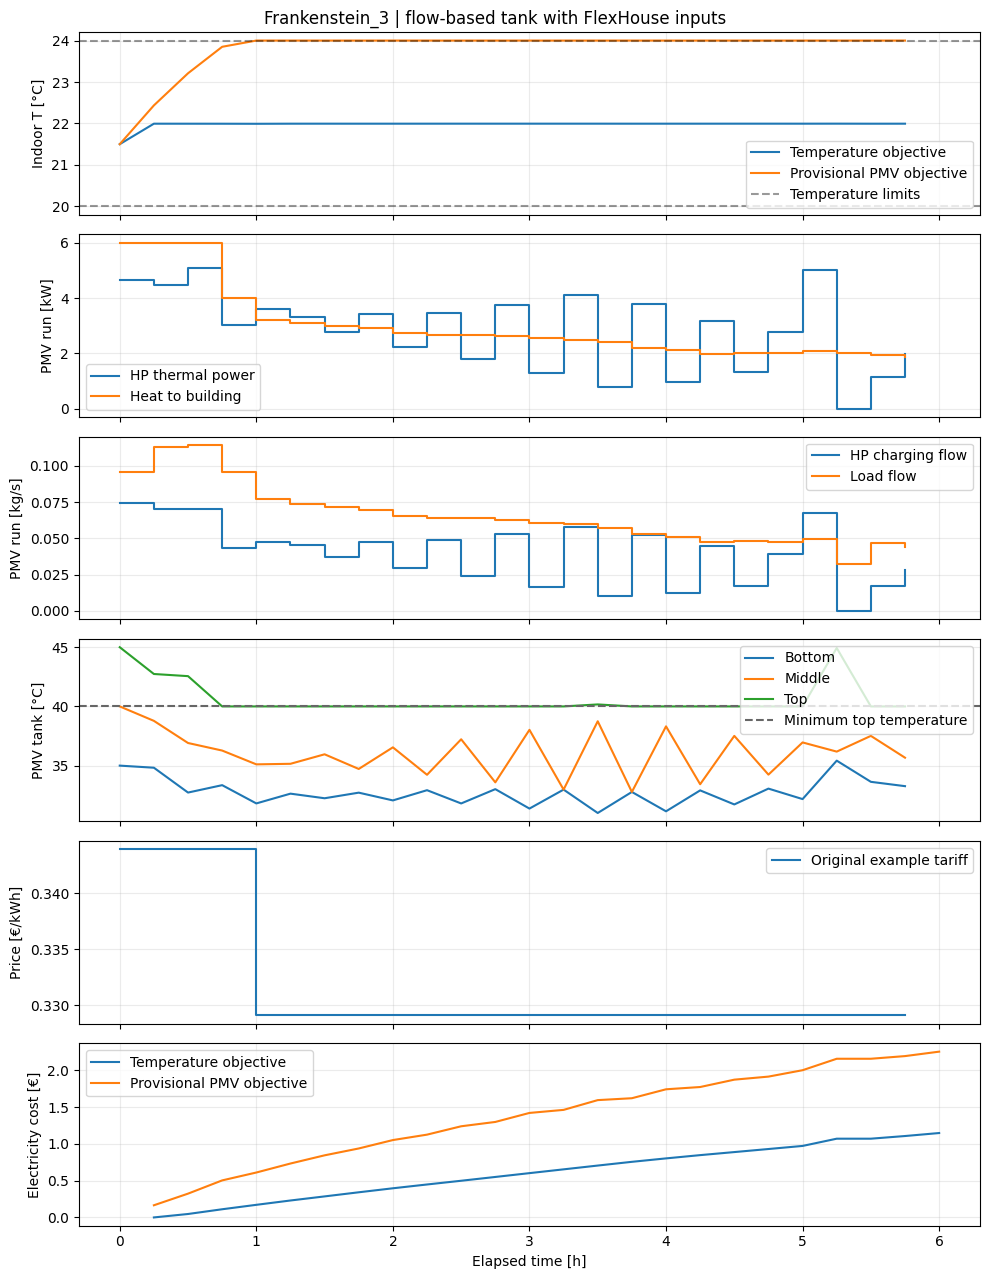

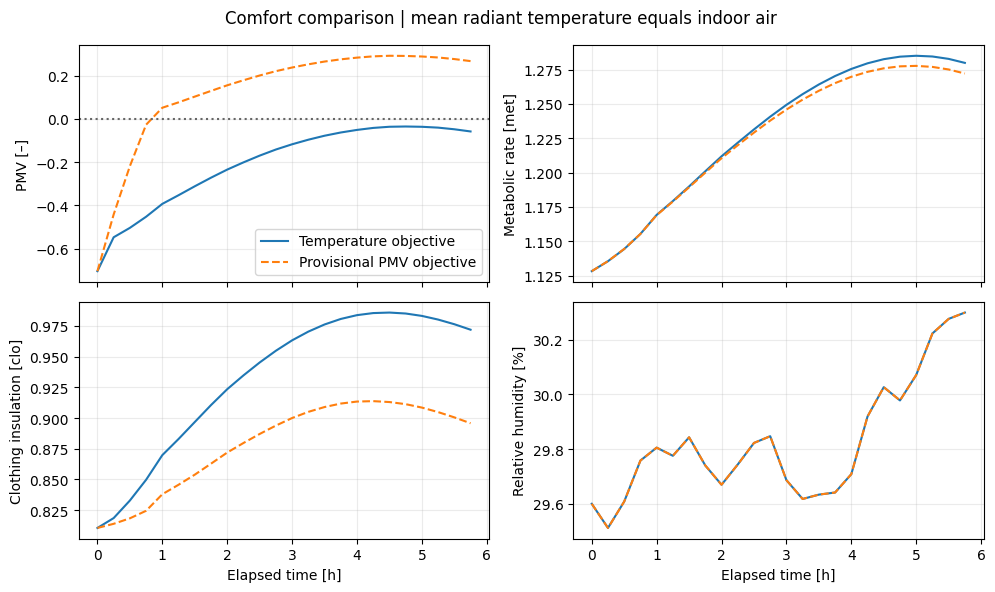

In [76]:
baseline = results_by_mode["temperature"]
results = results_by_mode["pmv_test"]
t = results["elapsed_h"]
fig, axes = plt.subplots(6, 1, figsize=(10, 13), sharex=True)
fig.suptitle("Frankenstein_3 | flow-based tank with FlexHouse inputs")

axes[0].plot(t, baseline["Ti_C"], label="Temperature objective")
axes[0].plot(t, results["Ti_C"], label="Provisional PMV objective")
axes[0].axhline(TI_MIN_C, color="k", linestyle="--", alpha=0.4, label="Temperature limits")
axes[0].axhline(TI_MAX_C, color="k", linestyle="--", alpha=0.4)
axes[0].set_ylabel("Indoor T [°C]")

axes[1].step(t, results["Q_hp_kw"], where="post", label="HP thermal power")
axes[1].step(t, results["Q_build_kw"], where="post", label="Heat to building")
axes[1].set_ylabel("PMV run [kW]")

axes[2].step(t, results["m_dot_hp_kg_s"], where="post", label="HP charging flow")
axes[2].step(t, results["m_dot_load_kg_s"], where="post", label="Load flow")
axes[2].set_ylabel("PMV run [kg/s]")

axes[3].plot(t, results["T_tank_bottom_C"], label="Bottom")
axes[3].plot(t, results["T_tank_middle_C"], label="Middle")
axes[3].plot(t, results["T_tank_top_C"], label="Top")
axes[3].axhline(T_SUPPLY_MIN_C, color="0.4", linestyle="--", label="Minimum top temperature")
axes[3].set_ylabel("PMV tank [°C]")

axes[4].step(t, results["price_eur_per_kwh"], where="post", label="Original example tariff")
axes[4].set_ylabel("Price [€/kWh]")

axes[5].plot(t + DT_HOURS, baseline["cumulative_cost_eur"], label="Temperature objective")
axes[5].plot(t + DT_HOURS, results["cumulative_cost_eur"], label="Provisional PMV objective")
axes[5].set_ylabel("Electricity cost [€]")
axes[5].set_xlabel("Elapsed time [h]")
for ax in axes:
    ax.legend(loc="best")
    ax.grid(alpha=0.25)
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(2, 2, figsize=(10, 6), sharex=True)
fig.suptitle("Comfort comparison | mean radiant temperature equals indoor air")
for ax, column, label in zip(
    axes.flat, ["PMV", "MET", "CLO", "RH_pct"],
    ["PMV [–]", "Metabolic rate [met]", "Clothing insulation [clo]", "Relative humidity [%]"],
):
    ax.plot(t, baseline[column], label="Temperature objective")
    ax.plot(t, results[column], "--", label="Provisional PMV objective")
    ax.set_ylabel(label)
    ax.grid(alpha=0.25)
axes[0, 0].axhline(0, color="0.4", linestyle=":")
axes[0, 0].legend(loc="best")
for ax in axes[1]:
    ax.set_xlabel("Elapsed time [h]")
plt.tight_layout()
plt.show()